# Cancer Tumor Classification 
Version 2: PyTorch <n>
Date: 10/25/2026

In [37]:
import logging
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

import torch 
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score

## 1. Data Ingestion
Load data from scikit-learn's Wisconsin Breast Cancer dataset

In [38]:
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names

df = pd.DataFrame(X, columns=feature_names)

# Map numeric to descriptive labels
df['Diagnosis'] = pd.Series(y).map({0: 'Malignant', 1: 'Benign'})

logging.info(f"Data sucessfully ingested. Dimensions: {df.shape}")

## 2. EDA

In [39]:
missing = df.isnull().sum()
print(f"Missing values per column: {missing}" )
print()

# Check class distribution
class_counts = df['Diagnosis'].value_counts()
class_percentages = df['Diagnosis'].value_counts(normalize=True)*100

print("Class Distribution:")
for i, label in enumerate(class_counts.index): 
    count = class_counts.values[i]
    percentage = class_percentages.values[i]
    print(f"{label}: {count} samples ({percentage:.2f}%)")
print()

# Scale profiling
numeric_features = df.drop(columns=['Diagnosis'])
display(numeric_features.describe().T[['mean', 'std', 'min', 'max']])

Missing values per column: mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
Diagnosis                  0
dtype: int64

Class Distribution:
Benign: 357 samples (62.74%)
Malignant: 

,mean,std,min,max
mean radius,14.127292,3.524049,6.981000,28.11000
mean texture,19.289649,4.301036,9.710000,39.28000
mean perimeter,91.969033,24.298981,43.790000,188.50000
mean area,654.889104,351.914129,143.500000,2501.00000
mean smoothness,0.096360,0.014064,0.052630,0.16340
mean compactness,0.104341,0.052813,0.019380,0.34540
mean concavity,0.088799,0.079720,0.000000,0.42680
mean concave points,0.048919,0.038803,0.000000,0.20120
mean symmetry,0.181162,0.027414,0.106000,0.30400
mean fractal dimension,0.062798,0.007060,0.049960,0.09744


The classes are moderately imbalanced at 63% benign and 37% malignant, so every split is stratified. From the scale profling, we can see that feature scales differ by orders of magnitude, therefore, standardization must happen before PCA.

## 3. Data Standardization & Feature Engineering
The data will be spilt using a 80:20 train-test ratio. The training group will be spit again 80:20 to create a validation set. The validation set is used only for early stopping, and the test set is used for the final evaluation.

In [40]:
# stratified train-test split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=24)

# split train set to include have train and validataion 
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=24)

# pca fitting v2
scaler = StandardScaler().fit(X_train)  # scale to train set
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=2).fit(X_train_scaled)
prep = lambda x: pca.transform(x).astype(np.float32)

X_train_pca = prep(X_train_scaled)
X_val_pca = prep(X_val_scaled)
X_test_pca = prep(X_test_scaled)

# check variance data
explained_var = pca.explained_variance_ratio_
total_var = explained_var.sum()*100
print(f"Variance retained: {total_var:.2f}%")

Variance retained: 62.54%


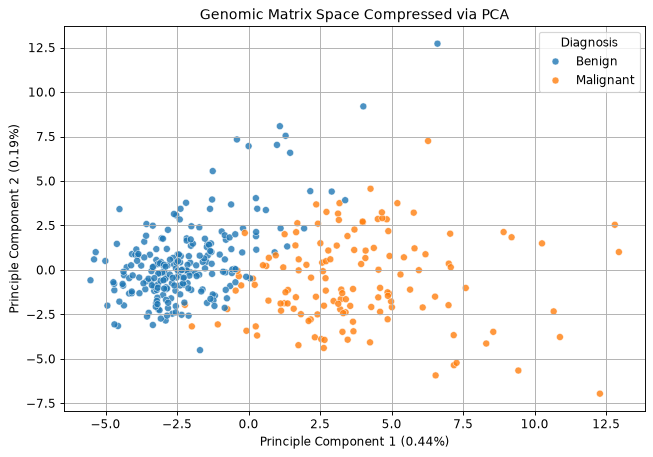

In [41]:
# create df with trained coordinates
# seaborn works best with structured pd df than numpy array
pca_df = pd.DataFrame(X_train_pca, columns=['PC1', 'PC2'])
pca_df['Diagnosis'] = pd.Series(y_train).map({0:'Malignant', 1:'Benign'})  # map temp column for graph legend 

# plot compressed graph
plt.figure(figsize=(9,6))  # create graph container
sb.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Diagnosis', alpha=0.8)  # generate and map points on graph

# add annotations to graph
plt.title("Genomic Matrix Space Compressed via PCA")
plt.xlabel(f"Principle Component 1 ({explained_var[0]:.2f}%)")
plt.ylabel(f"Principle Component 2 ({explained_var[1]:.2f}%)")
plt.grid(True)
plt.show()

## 4. PyTorch Pipeline
Use `TensorDataset` and `DataLoader` to handle batching and shuffling.

In [42]:
def make_loader(X_pca, labels, shuffle):
    """
    Create a loader to feed dataset into the model in batches
    Args:
        X_pca: PCA train, val, or test sets (X_train_pca, X_val_pca X_test_pca)
        labels: y_train, y_val, or y_test 
        shuffle (bool): reorders samples every epoch so the model does not see the data in the same order each time
    """
    ds = TensorDataset(
        torch.from_numpy(X_pca), 
        torch.from_numpy(labels.astype(np.float32))
        )  # pair each row of features with its labels

    # feeds dataset to the model in batches of 32
    return DataLoader(ds, batch_size=32, shuffle=shuffle)
    
train_dl = make_loader(X_train_pca, y_train, shuffle=True)

## 5. Model Training and Evaluation functions
Because PyTorch does not have a built-in solver, like `.fit()` function from sklearn, we will need to write out the training steps manually. This includes batching data, model definition, loss function, optimization, training loop, stopping, and prediction.  

In this section, I will create the functions and pipelines that will be used for training and evaluation. 

In [43]:
# Model definition
def make_mlp(dim):
    """
    MLP: multilayer perceptron is the simplest standard type of neural network where each layer's output feeds the next
    """
    mlp = nn.Sequential(
        nn.Linear(dim, 32),
        nn.ReLU(), 
        nn.Dropout(0.2),
        nn.Linear(32, 16),
        nn.ReLU(),
        nn.Linear(16, 1)
    )
    return mlp

# Loss function
loss_function = nn.BCEWithLogitsLoss()

X_val_t, y_val_t = torch.from_numpy(X_val_pca), torch.from_numpy(y_val.astype(np.float32))

@torch.no_grad()  # turns off gradient tracking 
def predict_logits(model, pca_set):
    """
    Converts numpy array to a tensor, run forward pass, drop extra dimensions, and convert back to numpy for sklearn metrics
    """
    model.eval()
    return model(torch.from_numpy(pca_set)).squeeze(1).numpy()

def train_mlp(seed, max_epochs=300, patience=20, lr=1e-3, weight_decay=1e-4):
    """
    Train an MLP with Adam and early stopping on validation loss.

    Args:
        seed (int): for reproducibility
        max_epochs (int): max number of passes over the training data
        patience (int): max number of epochs without improvement before stopping
        lr (float): learning rate
        weight_decay (float): penalty that discourages large weights
    
    Returns:
        model: trained MLP model with best-validation weights loaded
        history (list[tuple[float, float]]): per-epoch (train_loss, val_loss)
    """
    torch.manual_seed(seed)
    model = make_mlp(2)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)  # create optimizer (algorithm updates weights and it adapts the step sizer per weight)
    
    best_loss = float('inf')
    best_state = None
    count = 0
    history = []
    for epoch in range(max_epochs):
        model.train()
        running = 0.0
        for features, labels in train_dl:
            opt.zero_grad()
            loss = loss_function(model(features).squeeze(1), labels)  # forward 
            loss.backward()  # backward
            opt.step()

            # add up batch loss weighted by batch size 
            running += loss.item() * len(features)

        model.eval()
        with torch.no_grad():
            val_loss = loss_function(model(X_val_t).squeeze(1), y_val_t).item()
        history.append((running/len(X_val_pca), val_loss))  # record avg training loss and val loss for training curves
        
        if val_loss < best_loss:
            best_loss = val_loss  # update best_loss
            best_state = copy.deepcopy(model.state_dict())  # save a copy of the weights
            count = 0  # reset count
        else:
            # no improvement => update count
            count += 1
            if count >= patience:
                # early stop
                break
    
    model.load_state_dict(best_state)
    return model, history


In [44]:
def compute_metrics(y_true, y_pred, y_score):
    report = classification_report(
        y_true, y_pred, target_names=['Malignant', 'Benign'], output_dict=True
    )
    
    accuracy = report['accuracy']*100
    sensitivity = report['Malignant']['recall']
    specificity = report['Benign']['recall']
    auc = roc_auc_score(y_true, y_score)

    return {
        'accuracy': accuracy,
        'sensitivity (malignant recall)': sensitivity,
        'specificity (benign recall)': specificity,
        'AUC': auc
    }


## 6. Train and Evaluate
Now that the pipeline has been created, we can implement it. 

In [49]:
mlp_runs = []
models = []
histories = []
for seed in range(5):
    model, history = train_mlp(seed)
    logits = predict_logits(model, X_test_pca)
    pred = (logits > 0).astype(int)
    mlp_runs.append(compute_metrics(y_test, pred, logits))
    models.append(model)
    histories.append(history)
    logging.info(f"seed {seed}: {len(history)} epochs, test acc {mlp_runs[-1]['accuracy']:.4f}")

runs = pd.DataFrame(mlp_runs, index=[f"seed {s}" for s in range(5)])
display(runs.round(2))                          # per-seed results
display(runs.agg(['mean', 'std']).T.round(2))

,accuracy,sensitivity (malignant recall),specificity (benign recall),AUC
seed 0,93.86,0.9,0.96,0.98
seed 1,92.98,0.9,0.94,0.98
seed 2,92.98,0.9,0.94,0.98
seed 3,92.98,0.9,0.94,0.98
seed 4,93.86,0.9,0.96,0.98


,mean,std
accuracy,93.33,0.48
sensitivity (malignant recall),0.90,0.00
specificity (benign recall),0.95,0.01
AUC,0.98,0.00


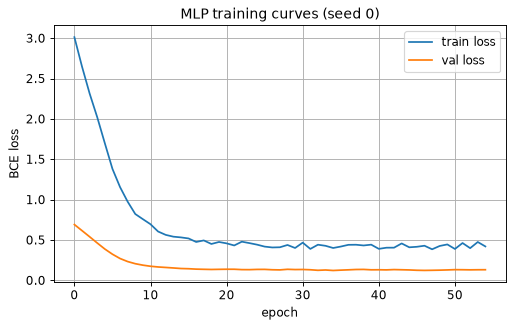

              precision    recall  f1-score   support

   Malignant       0.93      0.90      0.92        42
      Benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



In [46]:
history = np.array(histories[0])
plt.figure(figsize=(7, 4))
plt.plot(history[:, 0], label='train loss')
plt.plot(history[:, 1], label='val loss')
plt.xlabel('epoch'); plt.ylabel('BCE loss'); plt.legend(); plt.grid(True)
plt.title("MLP training curves (seed 0)")
plt.show()

logits0 = predict_logits(models[0], X_test_pca)
print(classification_report(y_test, (logits0 > 0).astype(int),
                            target_names=['Malignant', 'Benign']))

torch.save(models[0].state_dict(), 'tumor_mlp_seed0.pt')

Validation loss falls quickly and flattens after about 20 epochs without rising, so there is no sign of overfitting. Training loss sits higher because it is measured with dropout on and averaged over each epoch. Across 5 seeds, the model reaches about 93% test accuracy (93.3% mean), detecting 38 of 42 malignant tumors (90.5% sensitivity) with 95.0% specificity and an AUC of 0.979. Results are nearly identical across seeds, with accuracy varying by at most one test sample, so training is stable. That variation covers only random initialization, though, not the choice of train/test split, and with 114 test samples one sample is worth about 0.9 percentage points. The model uses 2 principal components, which limits the information it sees, and a comparison with the scikit-learn SVM is in the README.